# Разработка A/B-тестирования и анализ результатов

Заказчик: компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В их приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Необходимо рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных



### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных

In [ ]:
# Импортируем библиотеку pandas
import pandas as pd

import matplotlib.pyplot as plt

In [ ]:
# Загружаем данные в датафрем sessions history
sessions_history = pd.read_csv('')

In [ ]:
# Выведем первые 5 строк датафрейма
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными


In [ ]:
# Посчитаем количество уникальных сессий для каждого уникального пользователя
distinct_session = sessions_history.groupby('user_id')['session_id'].nunique().reset_index()
distinct_session.head()

,user_id,session_id
0,00005FB6A13A6FBE,2
1,0000B15A18D77ED9,3
2,0000C4E3A4A571A9,2
3,000293FAF9E67A81,4
4,00029C5AE889A6C3,2


In [ ]:
# Найдем максимальное количество сессий на пользователя
max_sessions = distinct_session['session_id'].max()
max_sessions

10

In [ ]:
# Найдем user_id пользователя с максимальным количеством сессий
top_user_id = distinct_session[distinct_session['session_id'] == max_sessions]['user_id'].iloc[0]
top_user_id

'10E0DEFC1ABDBBE0'

In [ ]:
# Выведем всю информацию для данного пользователя
top_user = sessions_history[sessions_history['user_id'] == top_user_id]
top_user

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций


In [ ]:
# Посчитаем количество уникальных и зарегистрированных пользователей для каждой даты
distinct_users = sessions_history.groupby('session_date')['user_id'].nunique().reset_index()
registered_users = sessions_history[sessions_history['registration_flag'] == 1].groupby('session_date')['user_id'].nunique().reset_index()
distinct_users.head(), registered_users.head()

(  session_date  user_id
 0   2025-08-11     3919
 1   2025-08-12     6056
 2   2025-08-13     8489
 3   2025-08-14    10321
 4   2025-08-15    14065,
   session_date  user_id
 0   2025-08-11      169
 1   2025-08-12      336
 2   2025-08-13      464
 3   2025-08-14      625
 4   2025-08-15      840)

In [ ]:
# Объединим полученные данные
users = distinct_users.merge(registered_users, on = 'session_date', how = 'left')
users.head()

,session_date,user_id_x,user_id_y
0,2025-08-11,3919,169
1,2025-08-12,6056,336
2,2025-08-13,8489,464
3,2025-08-14,10321,625
4,2025-08-15,14065,840


In [ ]:
# Переименуем столбцы для корректного обращения к ним
users.columns = ['session_date', 'distinct_users', 'registered_users']

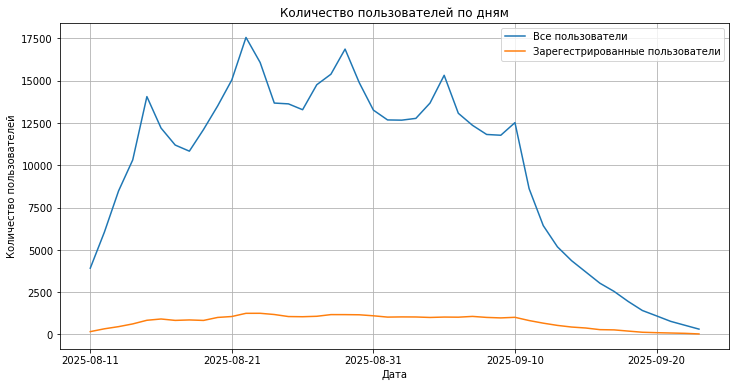

In [ ]:
# Построим линейный график с общим числом пользователей и с числом зарегистрированных
users.plot(x = 'session_date',
          y = ['distinct_users', 'registered_users'],
          kind = 'line',
          figsize = (12, 6))

plt.title('Количество пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.grid(True)
plt.legend(['Все пользователи', 'Зарегестрированные пользователи'])

plt.show()

In [ ]:
# Посчитаем долю зарегистрированных пользователей от общего числа
users['share'] = users['registered_users']/users['distinct_users']
users.head()

,session_date,distinct_users,registered_users,share
0,2025-08-11,3919,169,0.043123
1,2025-08-12,6056,336,0.055482
2,2025-08-13,8489,464,0.054659
3,2025-08-14,10321,625,0.060556
4,2025-08-15,14065,840,0.059723


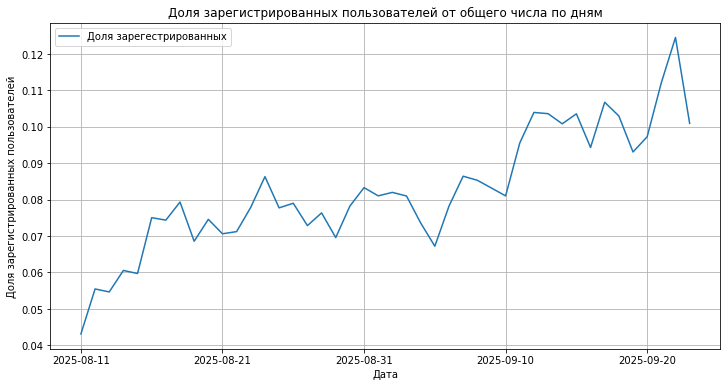

In [ ]:
# Построим линейный график с долей зарегистрированных пользователей
users.plot(x = 'session_date',
          y = 'share',
          kind = 'line',
          figsize = (12, 6))

plt.title('Доля зарегистрированных пользователей от общего числа по дням')
plt.xlabel('Дата')
plt.ylabel('Доля зарегистрированных пользователей')
plt.grid(True)
plt.legend(['Доля зарегистрированных'])

plt.show()

На полученных графиках видно, что за весь период доля зарегистрированных пользователей не превышает 13% от общего числа пользователей. Максимальное количество пользователей наблюдается в конце августа.

После 10 сентября количество пользователей, как общее, так и зарегистрированное, постепенно снижается. Однако доля зарегистрированных при этом растет.

Это может говорить о том, что зарегестрированные пользователи удерживаются лучше, чем незарегестрированные - регистрация может быть связана с более высокой вовлеченностью пользователей.

Но подобное снижение пользовательской активности выглядит существенным и требует дополнительного анализа причин оттока.

#### 1.4. Анализ числа просмотренных страниц


In [ ]:
# Найдем количество первых сессий для каждого значения количества просмотренных страниц
first_sessions = sessions_history[sessions_history['session_number'] == 1]
pages = first_sessions.groupby('page_counter')['session_id'].count(). reset_index()
pages

,page_counter,session_id
0,1,8978
1,2,32494
2,3,50939
3,4,32739
4,5,8075
5,6,777
6,7,37


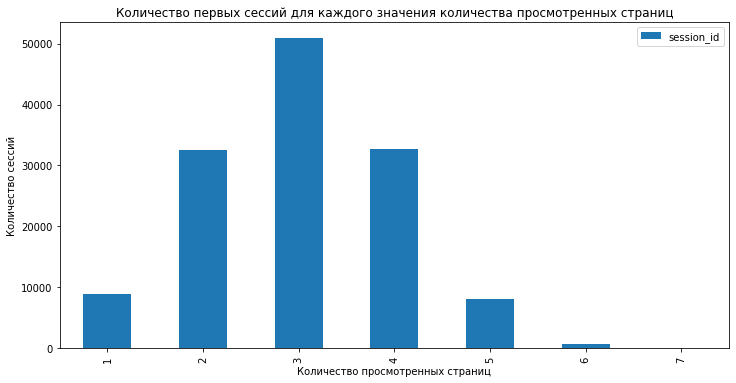

In [ ]:
# Построим столбчатую диаграмму количества первых сессий по просмотренным страницам
pages.plot(x = 'page_counter',
          y = 'session_id',
          kind = 'bar',
          figsize = (12, 6))

plt.title('Количество первых сессий для каждого значения количества просмотренных страниц')
plt.xlabel('Количество просмотренных страниц')
plt.ylabel('Количество сессий')

plt.show()

Чаще всего во время первой сессии пользователи просматривают 3 страницы, а также большое количество пользователей посещает 2 или 4 страницы.

Число пользователей резко снижается при просмотре 5 и более страниц. Это может говорить о том, что большинство ограничивается сравнительно коротким знакомством с приложением и не переходит к полноценному просмотру во время первой сессии, что может негативно сказаться на удержании пользователей, их дальнейшей регистрации и оплате подписки.

#### 1.5. Доля пользователей, просмотревших более четырёх страниц


In [ ]:
# Добавим поле с признаком успешной первой сессии
first_sessions = first_sessions.copy()
first_sessions['good_session'] = (first_sessions['page_counter'] >= 4).astype(int)
first_sessions.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,good_session
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone,0
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android,1
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC,1
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android,1
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android,0


In [ ]:
# Посчитаем среднее значение доли успешных первых сессий по дням
shape_good_sessions = first_sessions.groupby('session_date')['good_session'].mean().reset_index()
shape_good_sessions.head()

,session_date,good_session
0,2025-08-11,0.312835
1,2025-08-12,0.298344
2,2025-08-13,0.306861
3,2025-08-14,0.319098
4,2025-08-15,0.311114


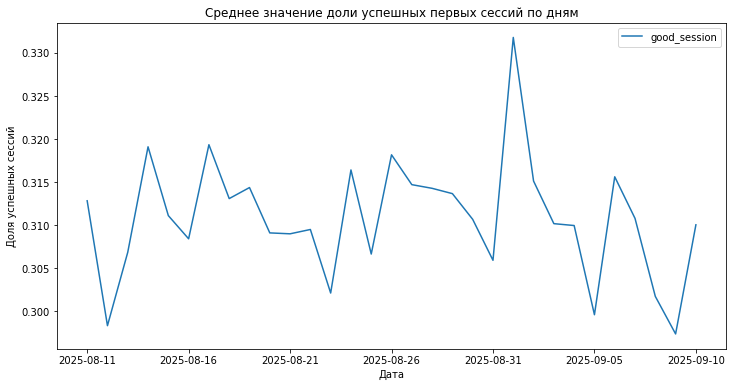

In [ ]:
# Построим график
shape_good_sessions.plot(x = 'session_date',
                        y = 'good_session',
                        kind = 'line',
                        figsize = (12,6))

plt.title('Среднее значение доли успешных первых сессий по дням')
plt.xlabel('Дата')
plt.ylabel('Доля успешных сессий')

plt.show()

Доля успешных первых сессий на протяжении всего рассматриваемого периода остается относительно стабильной и в среднем составляет около 30-32%. Это позволяет использовать показатель как базовый ориентир при планировании A/B-теста.

При этом только треть пользователей во время первой сессии просматривают 4 и более страниц - имеется потенциал для улучшения вовлеченности новых пользователей.

### 2. Подготовка к тесту

#### 2.1. Расчёт размера выборки


In [ ]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 1 - beta  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.03  # Минимальный детектируемый эффект
effect_size = proportion_effectsize(p, p*(1 + mde))

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

In [ ]:
from math import ceil

# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = distinct_users['user_id'].mean()

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil((sample_size * 2)/ avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {int(avg_daily_users)} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907 пользователей в день составит 9 дней


Нужно собрать не менее 41040 пользователей для каждой группы: при равном делении между группами общий размер должен составлять не менее 82080 пользователей. Для набора необходимой выборки потребуется 9 дней.

### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей


In [ ]:
# Загрузим данные в датафрейм sessions_test_part
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')
sessions_test_part.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [ ]:
# Посчитаем количество уникальных пользователей в каждой группе
test_groups = sessions_test_part.groupby('test_group')['user_id'].nunique().reset_index()
test_groups

,test_group,user_id
0,A,1477
1,B,1466


In [ ]:
# Распределим значения
users_a = test_groups[test_groups['test_group'] == 'A']['user_id'].iloc[0]
users_b = test_groups[test_groups['test_group'] == 'B']['user_id'].iloc[0]
users_a, users_b

(1477, 1466)

In [ ]:
# Посчитаем процентную разницу
difference = 100* abs(users_a - users_b)/ users_a
print(f'{round(difference, 2)}')

0.74


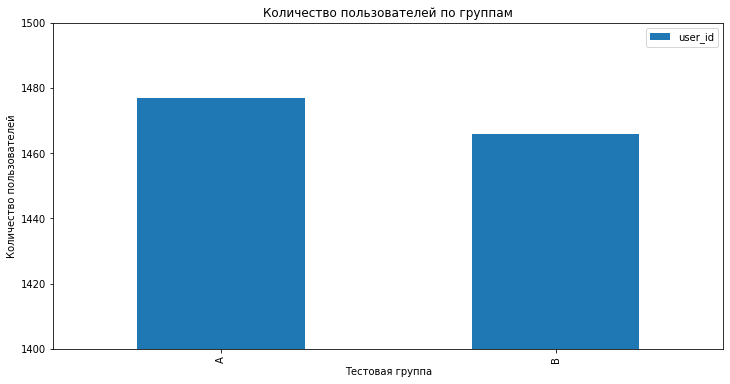

In [ ]:
# Построим визуализацию
test_groups.plot(x = 'test_group',
                y = 'user_id',
                kind = 'bar',
                figsize = (12,6))

plt.title('Количество пользователей по группам')
plt.xlabel('Тестовая группа')
plt.ylabel('Количество пользователей')
plt.ylim(1400, 1500)

plt.show()

Количество в группах A и B практически одинаково, процентная разница составила всего 0.74%. Распределение пользователей между группами является достаточно равномерным, однако необходимо проверить пересечение групп.

#### 3.2. Проверка пересечений пользователей


In [ ]:
# Найдем количество пользователей, которые входят в обе группы
group_a = sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id']
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id']
intersection = list(set(group_a) & set(group_b))
len(intersection)

0

Нет пользователей, которые встречаются одновременно в группах A и B. Группы независимы.

#### 3.3. Равномерность разделения пользователей по устройствам



In [ ]:
# Расчитаем долю каждого типа устройства для пользователей из группы А
device_a = sessions_test_part[sessions_test_part['test_group'] == 'A'].groupby('device')['user_id'].nunique().reset_index()
device_a['share'] = round(device_a['user_id'] / device_a['user_id'].sum()* 100, 2)
device_a

,device,user_id,share
0,Android,656,44.41
1,Mac,156,10.56
2,PC,369,24.98
3,iPhone,296,20.04


In [ ]:
# Расчитаем долю каждого типа устройства для пользователей из группы B
device_b = sessions_test_part[sessions_test_part['test_group'] == 'B'].groupby('device')['user_id'].nunique().reset_index()
device_b['share'] = round(device_b['user_id'] / device_b['user_id'].sum() *100, 2)
device_b

,device,user_id,share
0,Android,668,45.57
1,Mac,148,10.10
2,PC,381,25.99
3,iPhone,269,18.35


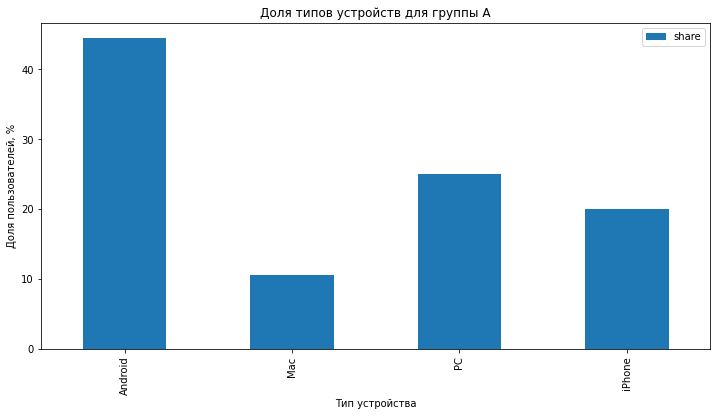

In [ ]:
# Построим график для группы А
device_a.plot(x = 'device',
             y = 'share',
             kind = 'bar',
             figsize = (12,6))
plt.title('Доля типов устройств для группы А')
plt.xlabel('Тип устройства')
plt.ylabel('Доля пользователей, %')

plt.show()

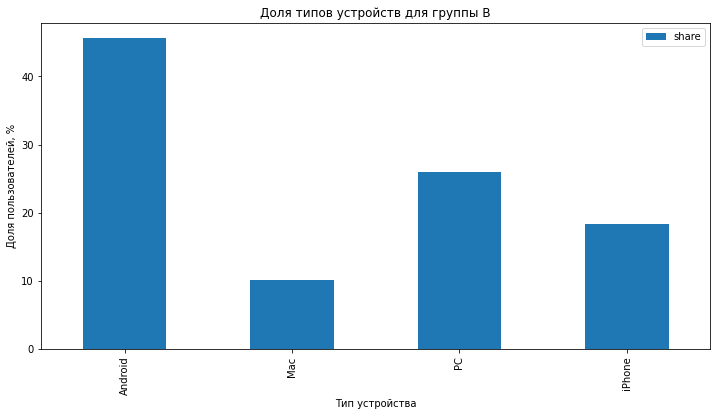

In [ ]:
# Построим график для группы B
device_b.plot(x = 'device',
             y = 'share',
             kind = 'bar',
             figsize = (12,6))
plt.title('Доля типов устройств для группы B')
plt.xlabel('Тип устройства')
plt.ylabel('Доля пользователей, %')

plt.show()

Распределение пользователей по типам устройств в группах А и В достаточно равномерное: в обеих группах наибольшую долю составляют владельцы Android (44-45%), затем пользователи PC - около 25%, iPhone - около 19-20% и Mac - около 10%. Различия в результатах теста с большей вероятностью будут связаны с тестируемые изменениями, а не с различиями в используемых устройствах.

#### 3.4. Равномерность распределения пользователей по регионам


In [ ]:
region_a = sessions_test_part[sessions_test_part['test_group'] == 'A'].groupby('region')['user_id'].nunique().reset_index()
region_a['share'] = round(region_a['user_id']/ region_a['user_id'].sum() * 100, 2)
region_a

,region,user_id,share
0,CIS,644,43.60
1,EU,224,15.17
2,MENA,609,41.23


In [ ]:
region_b = sessions_test_part[sessions_test_part['test_group'] == 'B'].groupby('region')['user_id'].nunique().reset_index()
region_b['share'] = round(region_b['user_id']/ region_b['user_id'].sum() * 100, 2)
region_b

,region,user_id,share
0,CIS,645,44.0
1,EU,217,14.8
2,MENA,604,41.2


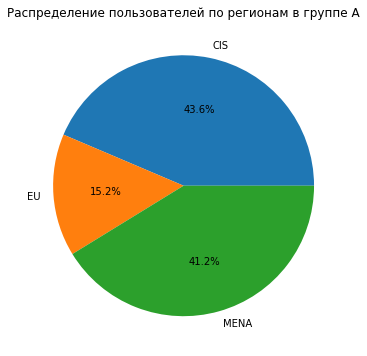

In [ ]:
region_a.set_index('region')['share'].plot(kind = 'pie',
             figsize = (12,6),
             autopct = '%1.1f%%')

plt.title('Распределение пользователей по регионам в группе А')
plt.ylabel('')

plt.show()

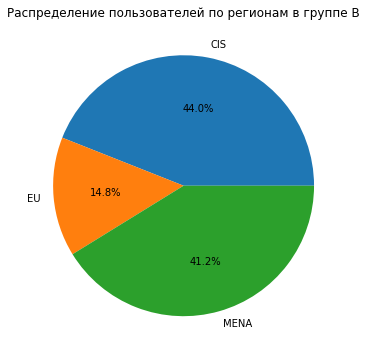

In [ ]:
region_b.set_index('region')['share'].plot(kind = 'pie',
             figsize = (12,6),
             autopct = '%1.1f%%')

plt.title('Распределение пользователей по регионам в группе B')
plt.ylabel('')

plt.show()

Распределение пользователей по регионам в группах, в целом, сопоставимо. Наибольшую долю пользователей в обеих группах составляют регионы CIS и MENA, а доля пользователей из EU заметно ниже.

В группе А немного большая доля пользователей из региона CIS, а в группе B из региона MENA. Различие выглядит несущественными и не указывают на серьезные несоответсвия в распределении пользователей между группами.

#### 3.5. Вывод после проверки A/B-теста


В ходе проверки корректности проведения A/B-теста было установлено, что количество пользователей в группах А и В практически совпадает. Процентная разница между группами составила менее 1%, что говорит об отсутствии существенного перекоса в распределении пользователей.

Проверка пересечения показала, что пользователи одновременно в тестовой и контрольной группах отсутствуют. Выборки являются независимыми, а распределение пользователей выполнено корректно.

Было проанализировано распределение пользователей по категориальным переменным: типам устройств и регионам. Существенных различий между группами А и В выявлено не было: распределения выглядят сопоставимыми.

На текущем этапе А/В-тест проходит корректно. Явных нарушений в распределении пользователей между группами не обнаружено. Данные можно использовать для дальнейшего анализа результатов эксперимента.

### 4. Проверка результатов A/B-теста


#### 4.1. Получение результатов теста и подсчёт основной метрики


In [ ]:
# Загрузим данные в датафрейм sessions_test
sessions_test = pd.read_csv('')
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B


In [ ]:
# Создадим поле с признаком успешной сессии
sessions_test['good_session'] = (sessions_test['page_counter'] >= 4).astype(int)
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


В качестве целевой метрики возьмем долю успешных первых сессий, где отражена доля пользователей, просмотревших 4 и более страниц в рамках первой сессии. Такая метрика отражает вовлеченность пользователей и удовлетворенность алгоритмом.

Тогда нулевая гипотеза (Н0) будет звучать так: Доля успешных первых сессий в группах А и В не различается, новый алгоритм не влияет на вовлеченность пользователей.

Альтернативная гипотеза (Н1): доля успешных первых сессий в группе В ВЫШЕ, чем в группе А, новый алгоритм рекомендаций влияет на вовлеченность пользователей.

В качестве прокси-метрик можно было бы использовать среднее количество просмотренных страниц, долю зарегистрированных пользователей, количество повторных посещений.

В качестве барьерных метрик можно было использовать статистику сбоев приложения, скорость загрузки, долю пользователей, покинувших приложение после первой страницы, количество обращений в поддержку.

#### 4.3. Сравнение доли успешных первых сессий

In [ ]:
# Отберем первые сессии среди успешных
first_session_test = sessions_test[sessions_test['session_number'] == 1]
first_session_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0
7,457F2674E87EF6E7,14F71C18BE2CEC08,2025-10-19,2025-10-19 11:49:11,2025-10-19,1,0,3,MENA,Mac,A,0
8,57F342451921D207,76EFA055599ADE3C,2025-10-19,2025-10-19 18:47:43,2025-10-19,1,0,3,CIS,PC,A,0
9,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B,0
13,504F268CCCDB2CA9,2879394D4E1AB0A2,2025-10-17,2025-10-17 17:00:45,2025-10-17,1,0,3,CIS,iPhone,A,0


In [ ]:
# Посчитаем долю успешных первых сессий для выборок А и В
good_sessions_test = first_session_test.groupby('test_group').mean().reset_index()
good_sessions_test

,test_group,session_number,registration_flag,page_counter,good_session
0,A,1.0,0.042475,3.017412,0.315724
1,B,1.0,0.039894,3.030034,0.314673


In [ ]:
good_a = good_sessions_test[good_sessions_test['test_group'] == 'A']['good_session'].iloc[0]
good_b = good_sessions_test[good_sessions_test['test_group'] == 'B']['good_session'].iloc[0]
difference = (abs(good_a-good_b)/good_a) * 100
print(f'Доля успешных сессий: в А {round(good_a ,4)}, в В {round(good_b, 4)}. Разница: {round(difference, 2)}%')

Доля успешных сессий: в А 0.3157, в В 0.3147. Разница: 0.33%


Доли успешных первых сессий в группах практически совпадают: 31.57% в группе А и 31.47% в группе В. Относительная разница между группами составила около 0.33%.

На текущем этапе заметного изменения в целевой метрике нет. Но для корректной интерпретации результатов необходимо дополнительно проверить, является ли различие статистически значимым.

#### 4.4. Насколько статистически значимо изменение ключевой метрики


In [ ]:
# Посчитаем размер выборок и количество успехов в группах А и В
n_a = first_session_test[first_session_test['test_group'] == 'A'].shape[0]
n_b = first_session_test[first_session_test['test_group'] == 'B'].shape[0]

m_a = first_session_test[(first_session_test['test_group'] == 'A') & (first_session_test['good_session'] == 1)].shape[0]
m_b = first_session_test[(first_session_test['test_group'] == 'B') & (first_session_test['good_session'] == 1)].shape[0]

n_a, n_b, m_a, m_b

(15162, 15416, 4787, 4851)

In [ ]:
# Рассчитаем долт успешных сессий
p_a = m_a/ n_a
p_b = m_b/ n_b
if (p_a*n_a > 10)&((1-p_a)*n_a > 10)&(p_b*n_b>10)&((1-p_b)*n_b>10):
    print('Предпосылка о достаточном количестве данных выполняется')
else:
    print('Предпосылка о достаточном количестве данных не выполняется')

Предпосылка о достаточном количестве данных выполняется


In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# Проведем тест
alpha = 0.05

stat_ztest, p_value_ztest = proportions_ztest([m_a, m_b],
                                             [n_a, n_b],
                                             alternative = 'smaller')
print(f'p-value = {round(p_value_ztest, 2)}')

if p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение')
else:
    print('Нулевая гипотеза не находит подтверждение')

p-value = 0.58
Нулевая гипотеза находит подтверждение


По результатам теста получено значение p-value 0.58, что существенно превышает выбранный уровень значимости 0.05.

Статистически значимых различий между долями успешных сессий в группах нет. Нулевая гипотеза не отвергается, новый алгоритм не оказал статистически значимого влияния на вовлеченность пользователей.

#### 4.5. Вывод по результатам A/B-эксперимента


Был проведен А/В-тест нового алгоритма рекомендаций, целью которого было повышение вовлеченности пользователей. В качестве ключевой метрики использовалась доля успешных первых сессий - доля пользователей, просмотревших 4 и более страниц во время первой сессии.

Перед запуском эксперимента были рассчитаны параметры теста: необходимый размер выборки составил 41040 пользователей для каждой группы; расчетная длительность теста 9 дней при среднем трафике около 9907 пользователей.

Распределение пользователей между группами выполнено корректно: размеры групп практически совпадают, пересечения пользователей отсутствуют, а распределения по устройствам и регионам являются сопоставимыми.

Доля успешных первых сессий составила 31.57%  в группе А и 31.47% в группе В. Относительное различие между группами минимально - около 0.33%.

Для оценки статистической значимости был проведен z-тест пропорций. Полученное значение p-value 0.58 превышает уровень значимости 0.05, поэтому статистически значимых различий между группами не обнаружено.

Таким образом, эксперимент не подтвердил гипотезу о положительном влиянии нового алгоритма на вовлеченность пользователей. На текущем этапе оснований для внедрения нового алгоритма на всех пользователей нет.